<a href="https://colab.research.google.com/github/Luiz-castilho/CalculoNumerico/blob/main/teste_sam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Clone e instalação do repositório oficial do SAM 2
!git clone https://github.com/facebookresearch/sam2.git
%cd sam2
!pip install -e .
!pip install opencv-python matplotlib

fatal: destination path 'sam2' already exists and is not an empty directory.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
  Created wheel for SAM-2: filename=sam_2-1.0-0.editable-py3-none-any.whl size=13841 sha256=563a9527ca2c0c347abce91cf9185dcf7c83781a2976e29af9d1f69b35cbf9d1
  Stored in directory: /tmp/pip-ephem-wheel-cache-u50uz_ce/wheels/64/e2/28/d1780fb444d6d91bdaddca8d1cc2203826a9783d0f6c5c6e84
Successfully built SAM-2
  Attempting uninstall: SAM-2
    Found existing installation: SAM-2 1.0
    Uninstalling SAM-2-1.0:
      Successfully uninstalled SAM-2-1.0


In [ ]:
# Baixar o checkpoint (Small)
!wget -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt

--2026-10-20 00:57:23--  https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.33.67.77, 13.33.67.42, 13.33.67.91, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.33.67.77|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184309650 (176M) [application/vnd.snesdev-page-table]
Saving to: ‘checkpoints/sam2_hiera_small.pt.1’

sam2_hiera_small.pt 100%[===================>] 175.77M   160MB/s    in 1.1s    

2026-10-20 00:57:24 (160 MB/s) - ‘checkpoints/sam2_hiera_small.pt.1’ saved [184309650/184309650]



/tmp/ipykernel_12424/3679166220.py:36: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):


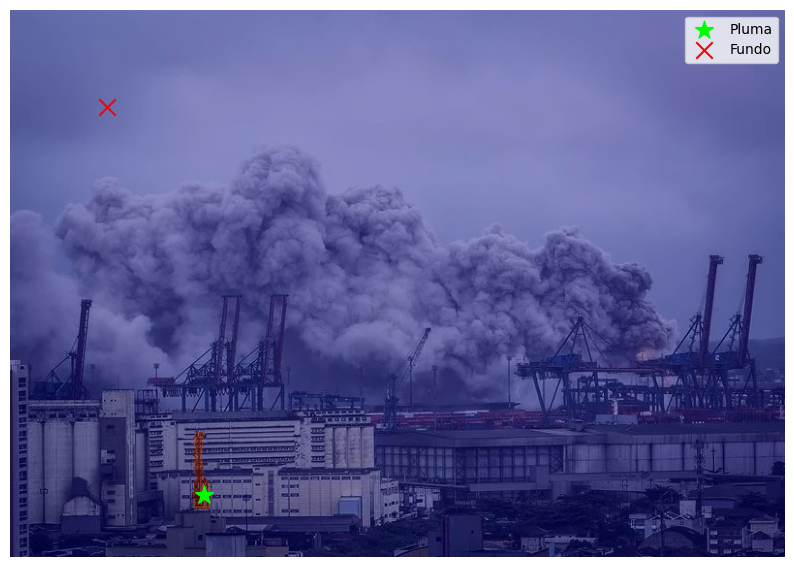

In [5]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

device = "cuda" if torch.cuda.is_available() else "cpu"

# Configurações do modelo
checkpoint = "checkpoints/sam2_hiera_small.pt"
model_cfg = "sam2_hiera_s.yaml"

# Construir o preditor
sam2_model = build_sam2(model_cfg, checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

# Carregar imagem
image_path = "/content/santos-gas.jpg"  # Substitua pelo seu arquivo
image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

# Codificar a imagem
predictor.set_image(image_np)

# Definir pontos na pluma (1 = positivo/pluma, 0 = negativo/céu ou solo)

#input_points = np.array([[500, 300], [100, 100]])  # [X, Y]
input_labels = np.array([1, 0])
input_points = np.array([
    [200, 500],  # Ponto 1 (estrela verde): centro da fumaça
    [100, 100]   # Ponto 0 (X vermelho): céu limpo no topo
])
# Predição
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    masks, scores, logits = predictor.predict(
        point_coords=input_points,
        point_labels=input_labels,
        multimask_output=True
    )

best_mask = masks[np.argmax(scores)]

# Visualização
plt.figure(figsize=(10, 8))
plt.imshow(image_np)
plt.imshow(best_mask, cmap="jet", alpha=0.45)
plt.scatter(input_points[input_labels == 1, 0], input_points[input_labels == 1, 1], color='lime', marker='*', s=180, label='Pluma')
plt.scatter(input_points[input_labels == 0, 0], input_points[input_labels == 0, 1], color='red', marker='x', s=140, label='Fundo')
plt.legend()
plt.axis("off")
plt.show()

/tmp/ipykernel_12424/369594759.py:49: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):


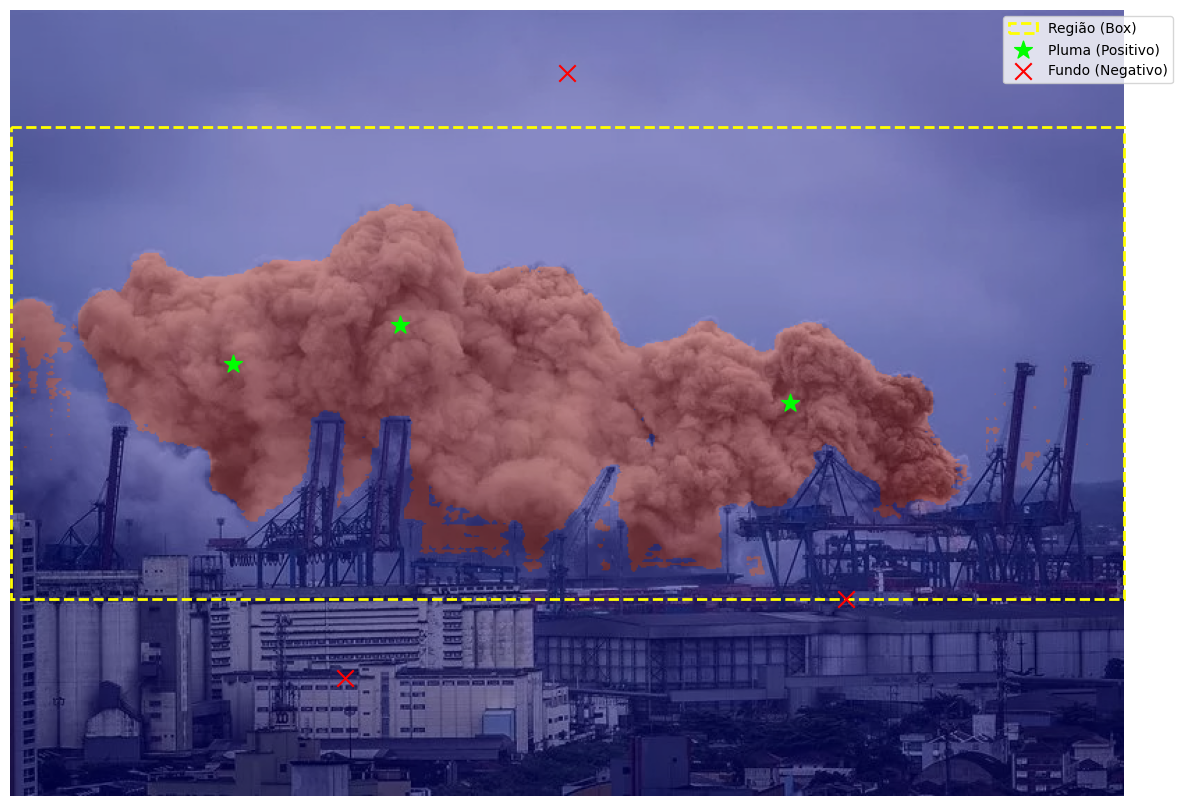

In [6]:
import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# Configurações do modelo
checkpoint = "checkpoints/sam2_hiera_small.pt"
model_cfg = "sam2_hiera_s.yaml"

# Construir o preditor
sam2_model = build_sam2(model_cfg, checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

# Carregar imagem
image_path = "/content/santos-gas.jpg"
image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

# Codificar a imagem
predictor.set_image(image_np)

# Dimensões da imagem (altura x largura)
h, w, _ = image_np.shape

# 1. Bounding box delimitando a região da fumaça: [x_min, y_min, x_max, y_max]
input_box = np.array([0, int(h * 0.15), w, int(h * 0.75)])

# 2. Pontos Positivos (1 = pluma) e Negativos (0 = céu / prédios / guindastes)
input_points = np.array([
    # Pontos positivos no corpo da fumaça [X, Y]
    [int(w * 0.35), int(h * 0.40)],  # Centro da pluma principal
    [int(w * 0.20), int(h * 0.45)],  # Asa esquerda
    [int(w * 0.70), int(h * 0.50)],  # Asa direita
    # Pontos negativos para barrar vazamento de máscara
    [int(w * 0.50), int(h * 0.08)],  # Céu no topo
    [int(w * 0.30), int(h * 0.85)],  # Edifício industrial abaixo
    [int(w * 0.75), int(h * 0.75)],  # Guindastes / containers
])

input_labels = np.array([1, 1, 1, 0, 0, 0])

# Predição combinando Box + Pontos
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
  masks, scores, logits = predictor.predict(
      point_coords=input_points,
      point_labels=input_labels,
      box=input_box[None, :],
      multimask_output=False,
  )

best_mask = masks[0]

# Visualização
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(image_np)
ax.imshow(best_mask, cmap="jet", alpha=0.45)

# Plotar Bounding Box
box_x, box_y = input_box[0], input_box[1]
box_w, box_h = input_box[2] - input_box[0], input_box[3] - input_box[1]
rect = patches.Rectangle(
    (box_x, box_y),
    box_w,
    box_h,
    linewidth=2,
    edgecolor="yellow",
    facecolor="none",
    linestyle="--",
    label="Região (Box)",
)
ax.add_patch(rect)

# Plotar pontos positivos e negativos
ax.scatter(
    input_points[input_labels == 1, 0],
    input_points[input_labels == 1, 1],
    color="lime",
    marker="*",
    s=180,
    label="Pluma (Positivo)",
)
ax.scatter(
    input_points[input_labels == 0, 0],
    input_points[input_labels == 0, 1],
    color="red",
    marker="x",
    s=140,
    label="Fundo (Negativo)",
)

ax.legend(loc="upper right")
ax.axis("off")
plt.tight_layout()
plt.show()

Dispositivo selecionado: cpu
Dimensões da imagem: 800x565 (Largura x Altura)


/tmp/ipykernel_12424/2479267240.py:102: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):


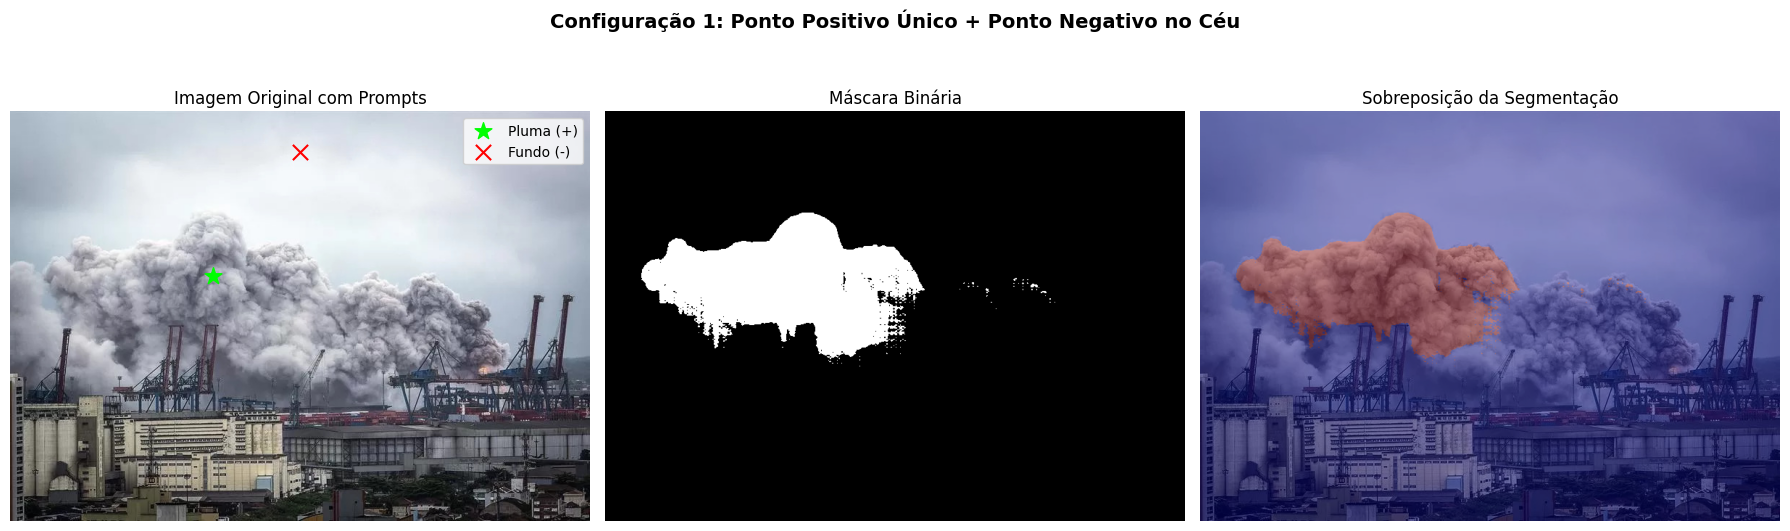

/tmp/ipykernel_12424/2479267240.py:120: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):


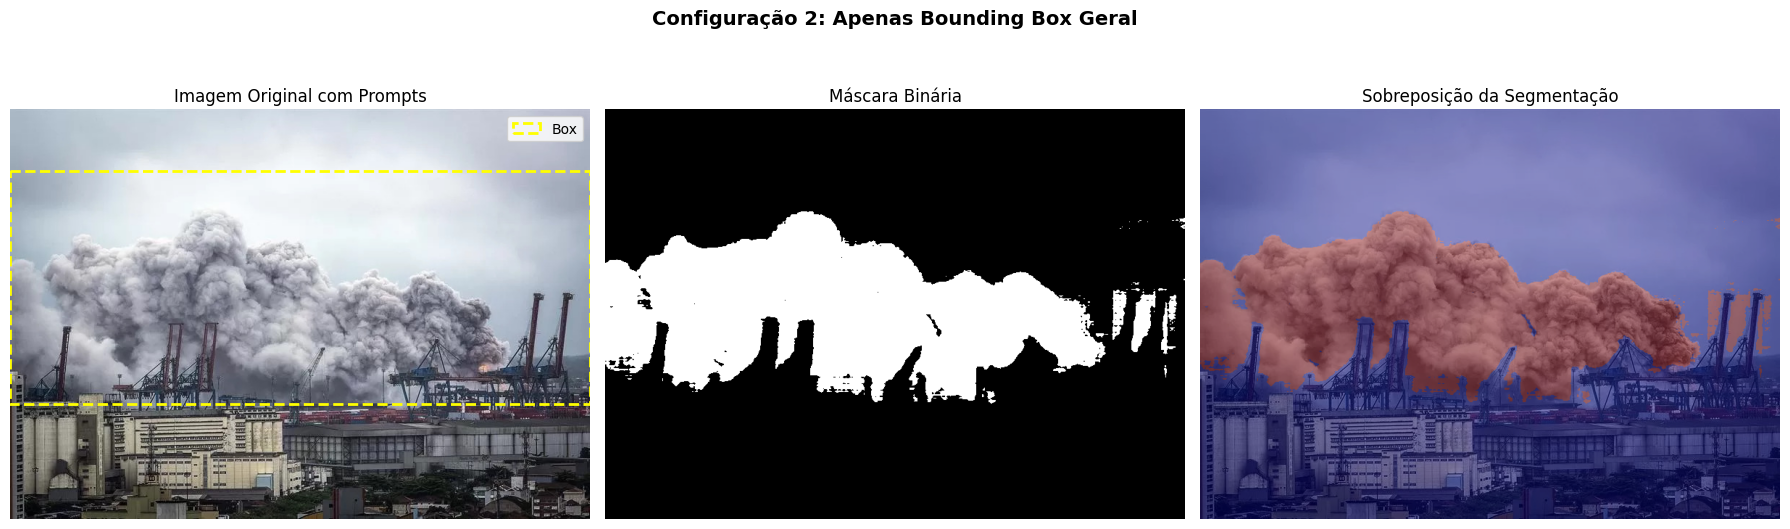

/tmp/ipykernel_12424/2479267240.py:151: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):


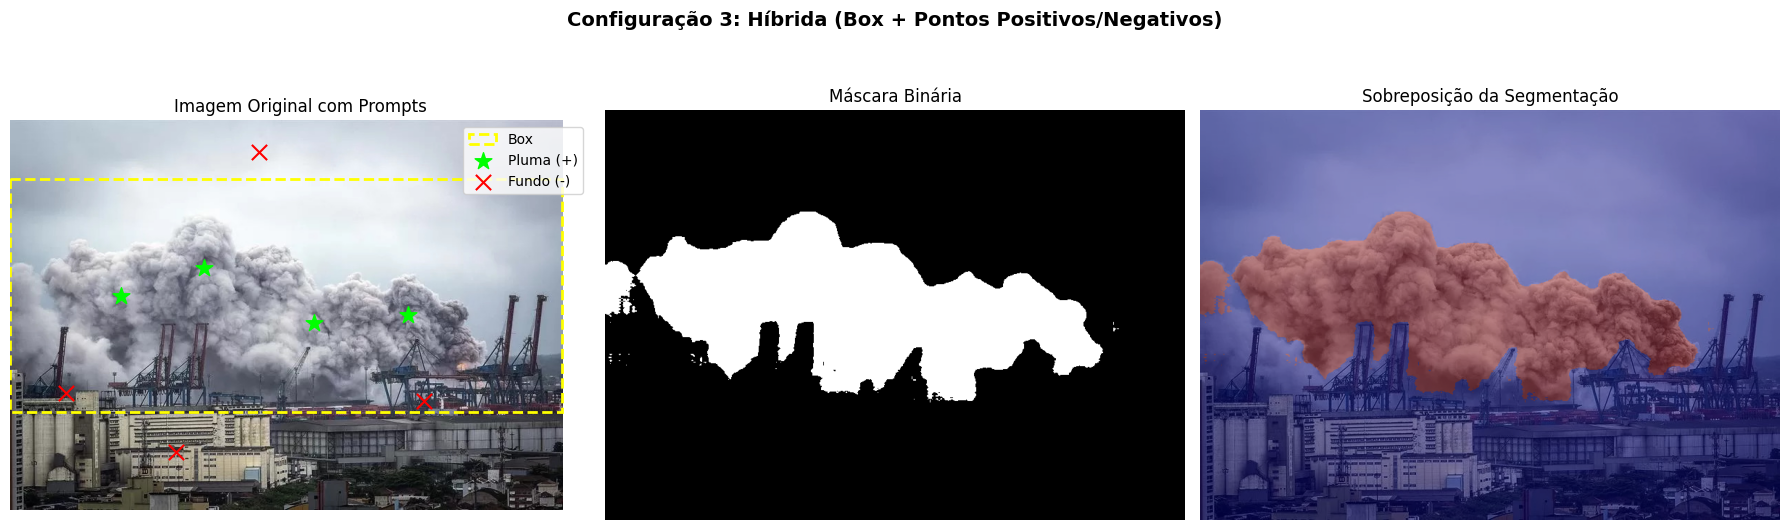

Cobertura da Máscara C1 (Ponto Único): 9.81% da imagem
Cobertura da Máscara C2 (Apenas Box):   23.77% da imagem
Cobertura da Máscara C3 (Aprimorada):  20.33% da imagem


In [10]:
# ==============================================================================
# ATIVIDADE PRÁTICA: SEGMENTAÇÃO DE PLUMA DE FUMAÇA COM SAM 2
# ==============================================================================

import os
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# ------------------------------------------------------------------------------
# 1. INICIALIZAÇÃO DO MODELO E CARREGAMENTO DA IMAGEM
# ------------------------------------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo selecionado: {device}")

# Checkpoints do modelo
checkpoint = "checkpoints/sam2_hiera_small.pt"
model_cfg = "sam2_hiera_s.yaml"

sam2_model = build_sam2(model_cfg, checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

# Caminho da imagem no Colab
image_path = "/content/santos-gas.jpg"
image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

h, w, _ = image_np.shape
print(f"Dimensões da imagem: {w}x{h} (Largura x Altura)")

# Codificação das características da imagem pelo SAM 2
predictor.set_image(image_np)

# ------------------------------------------------------------------------------
# 2. FUNÇÃO AUXILIAR DE VISUALIZAÇÃO LADO A LADO
# ------------------------------------------------------------------------------
def plot_results(image_np, mask, points=None, labels=None, box=None, title=""):
    """
    Exibe lado a lado:
    1. Imagem original com os prompts aplicados.
    2. Máscara binária pura (preto e branco).
    3. Máscara sobreposta à imagem original.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # 1. Imagem Original com Prompts
    axes[0].imshow(image_np)
    axes[0].set_title("Imagem Original com Prompts", fontsize=12)
    if box is not None:
        bx, by = box[0], box[1]
        bw, bh = box[2] - box[0], box[3] - box[1]
        rect = patches.Rectangle(
            (bx, by), bw, bh,
            linewidth=2, edgecolor='yellow', facecolor='none',
            linestyle='--', label='Box'
        )
        axes[0].add_patch(rect)
    if points is not None and labels is not None:
        pos_pts = points[labels == 1]
        neg_pts = points[labels == 0]
        if len(pos_pts) > 0:
            axes[0].scatter(pos_pts[:, 0], pos_pts[:, 1], color='lime', marker='*', s=160, label='Pluma (+)')
        if len(neg_pts) > 0:
            axes[0].scatter(neg_pts[:, 0], neg_pts[:, 1], color='red', marker='x', s=120, label='Fundo (-)')
    axes[0].legend(loc="upper right")
    axes[0].axis("off")

    # 2. Máscara Binária
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Máscara Binária", fontsize=12)
    axes[1].axis("off")

    # 3. Máscara Sobreposta
    axes[2].imshow(image_np)
    axes[2].imshow(mask, cmap="jet", alpha=0.45)
    axes[2].set_title("Sobreposição da Segmentação", fontsize=12)
    axes[2].axis("off")

    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------------------
# 3. EXPERIMENTOS COMPARATIVOS
# ------------------------------------------------------------------------------

# ----------------------------------------------------------------------
# Configuração 1: Ponto isolado ambíguo (Baseline problemático)
# ----------------------------------------------------------------------
pts_c1 = np.array([
    [int(w * 0.35), int(h * 0.40)],  # Ponto positivo no centro da fumaça
    [int(w * 0.50), int(h * 0.10)]   # Ponto negativo no céu
])
labels_c1 = np.array([1, 0])

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    masks_c1, scores_c1, _ = predictor.predict(
        point_coords=pts_c1,
        point_labels=labels_c1,
        multimask_output=True
    )
mask_c1 = masks_c1[np.argmax(scores_c1)]

plot_results(
    image_np, mask_c1, points=pts_c1, labels=labels_c1,
    title="Configuração 1: Ponto Positivo Único + Ponto Negativo no Céu"
)

# ----------------------------------------------------------------------
# Configuração 2: Apenas Caixa Delimitadora (Bounding Box pura)
# ----------------------------------------------------------------------
box_c2 = np.array([0, int(h * 0.15), w, int(h * 0.72)])

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    masks_c2, scores_c2, _ = predictor.predict(
        box=box_c2[None, :],
        multimask_output=False
    )
mask_c2 = masks_c2[0]

plot_results(
    image_np, mask_c2, box=box_c2,
    title="Configuração 2: Apenas Bounding Box Geral"
)

# ----------------------------------------------------------------------
# Configuração 3: Estratégia Híbrida Refinada (Solução Direta com masks[0])
# ----------------------------------------------------------------------
box_c3 = np.array([0, int(h * 0.15), w, int(h * 0.75)])

pts_c3 = np.array([
    # Pontos Positivos (corpo da pluma)
    [int(w * 0.20), int(h * 0.45)],
    [int(w * 0.35), int(h * 0.38)],
    [int(w * 0.55), int(h * 0.52)],
    [int(w * 0.72), int(h * 0.50)],
    # Pontos Negativos (barreiras contra fuga para o fundo)
    [int(w * 0.45), int(h * 0.08)],  # Céu/nuvens superiores
    [int(w * 0.30), int(h * 0.85)],  # Edifício do porto
    [int(w * 0.75), int(h * 0.72)],  # Base dos guindastes
    [int(w * 0.10), int(h * 0.70)]   # Estrutura vertical esquerda
])
labels_c3 = np.array([1, 1, 1, 1, 0, 0, 0, 0])

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    masks_c3, scores_c3, _ = predictor.predict(
        point_coords=pts_c3,
        point_labels=labels_c3,
        box=box_c3[None, :],
        multimask_output=False
    )

# Utilização direta de masks_c3[0], já alinhada com as dimensões (h, w) da imagem original
mask_c3 = masks_c3[0]

plot_results(
    image_np, mask_c3, points=pts_c3, labels=labels_c3, box=box_c3,
    title="Configuração 3: Híbrida (Box + Pontos Positivos/Negativos)"
)

# ------------------------------------------------------------------------------
# 4. AVALIAÇÃO QUANTITATIVA
# ------------------------------------------------------------------------------
area_c1 = np.sum(mask_c1) / mask_c1.size * 100
area_c2 = np.sum(mask_c2) / mask_c2.size * 100
area_c3 = np.sum(mask_c3) / mask_c3.size * 100

print(f"Cobertura da Máscara C1 (Ponto Único): {area_c1:.2f}% da imagem")
print(f"Cobertura da Máscara C2 (Apenas Box):   {area_c2:.2f}% da imagem")
print(f"Cobertura da Máscara C3 (Aprimorada):  {area_c3:.2f}% da imagem")

Para testar o SAM foi utilizado um caso se incêndio químico, afim de testar a detecção de pluma em uma imagem com menor contraste (a coloração da fumaça se mistura ao céu nublado), a versão original no qual pedi para o gemini gerar não era capaz de diferenciar ambos.

A segunda versão definiu alguns pontos positivos e outros negativos para delimitar a pluma.

A terceira criou 3 testes distintos, o primeiro com só dois pontos que nesse caso foi suficiente, para o segundo foi utilizada uma bounding box para auxiliar na detecção, porém é perceptível algumas imperfeições na extensão da pluma e próxima a ela. O terceiro utilizou uma junção dos dois metódos, o que acabou gerando uma detecção mais precisa nos detalhes,mas acabou deixando uma área da pluma de fora.